<a href="https://colab.research.google.com/github/musorsey-web/MDT/blob/main/lab_02_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ЛР №2. Виртуальные сенсоры и IoT-телеметрия

Основа: `robotics-course/05-perception/class.ipynb`.

Физический ESP32/MQTT-broker не требуется: IoT-поток моделируется локально как последовательность сообщений.

**Студент:** ____________________ **Группа:** __________ **Вариант:** ____

## Критерии оценки (20 баллов)

| Часть | Содержание | Баллы |
|---|---|---:|
| 1 | Модель физического процесса и виртуальные датчики | 5 |
| 2 | Телеметрия в формате сообщений и модель канала | 5 |
| 3 | Метрики качества телеметрии (обязательный минимум) | 2 |
| 4 | Графики: исходный и принятый ряды, ошибка, актуальность | 3 |
| 5 | Исследование влияния потерь и частоты, вывод | 3 |
| 6 | Методическое задание: фрагмент урока или игра для школьников | 2 |

## Смысл работы для будущего учителя

Любой школьный проект с датчиками устроен одинаково: **датчик измеряет → данные передаются →
человек видит результат на экране**. Датчик шумит и смещается, канал теряет и задерживает
сообщения, экран показывает последнее пришедшее значение. Работа учит измерять, сколько
теряется на каждом звене, и отвечает на вопрос: **как часто устройству отправлять данные?**

Три главных вывода, которые вы проверите на своих числах:

1. **Шум частотой не лечится** — погрешность прибора не уменьшается, если опрашивать его чаще.
2. **Потери бьют по свежести, а не по точности** — пропущенное сообщение делает данные на
   экране устаревшими.
3. **«Чаще» — не всегда «лучше»** — после точки насыщения рост частоты только расходует канал
   и батарейку.

В части 6 вы превратите один из этих выводов во фрагмент урока или игру для школьников.

In [41]:
VARIANT = 13
assert 1 <= VARIANT <= 25

In [42]:
from pathlib import Path
import subprocess, sys
repo=Path("robotics-course")
if not repo.exists():
    subprocess.run(["git","clone","--depth","1","--branch","2026",
                    "https://github.com/BosenkoTM/robotics-course.git",str(repo)],check=True)
perception=repo/"05-perception"
sys.path.insert(0,str(perception.resolve()))

In [43]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt

In [44]:
def variant_params(n):
    sensors=["Encoder","IMU","Encoder+IMU","LiDAR","Encoder+LiDAR"]
    freqs=[5,10,20,25,50]
    losses=[0,2,5,8,10]
    return {
        "sensor": sensors[(n-1)%5],
        "freq_hz": freqs[(n-1)//5],
        "noise_pct": [0.5,1.0,1.5,2.0,2.5][(n-1)%5],
        "loss_pct": losses[(n-1)//5],
        "seed": 200+n
    }

cfg = variant_params(VARIANT)
print(f"Вариант : {VARIANT}")
for k, v in cfg.items():
    print(f"  {k:<10}: {v}")

Вариант : 13
  sensor    : Encoder+IMU
  freq_hz   : 20
  noise_pct : 1.5
  loss_pct  : 5
  seed      : 213


In [45]:
from pathlib import Path
import subprocess
import sys

REPO_URL = "https://github.com/BosenkoTM/robotics-course.git"
repo = Path("robotics-course")

if not repo.exists():
    try:
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "2026",
                        REPO_URL, str(repo)], check=True, timeout=180,
                       capture_output=True)
    except Exception as err:                      # нет сети — работаем автономно
        print("Репозиторий не склонирован:", type(err).__name__)

for sub in ("04-mobile-robots", "05-perception"):
    path = (repo / sub).resolve()
    if path.exists():
        sys.path.insert(0, str(path))
        sys.path.insert(0, str(path / "lib"))

DiffDrive = None
try:
    from kinematic_models import DiffDrive          # 04-mobile-robots/lib
except Exception:
    try:
        from lib.kinematic_models import DiffDrive
    except Exception:
        DiffDrive = None

REPO_OK = DiffDrive is not None
print("Репозиторий доступен :", repo.exists())
print("DiffDrive из репозитория:", "да" if REPO_OK else "нет — используется встроенная модель")

Репозиторий доступен : True
DiffDrive из репозитория: да


In [46]:
import json
import math
import zipfile
from dataclasses import dataclass
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["font.size"] = 9

# --- параметры эксперимента, единые для всех вариантов
DEVICE_ID  = "robot01"
SIM_TIME   = 40.0        # длительность эксперимента, с (требуется не менее 30)
DT_TRUTH   = 0.001       # шаг «физической» модели, с (1 кГц)
WHEEL_R    = 0.05        # радиус колеса, м
WHEEL_BASE = 0.20        # колея, м

# --- полные шкалы датчиков: относительно них считается уровень шума в процентах
SCALE = {
    "encoder": 1.00,     # м/с   — максимальная линейная скорость
    "imu":     2.00,     # рад/с — полная шкала гироскопа
    "lidar":   5.00,     # м     — максимальная дальность
}
UNITS = {"encoder": "м/с", "imu": "рад/с", "lidar": "м"}

ENCODER_CPR   = 1024     # импульсов на оборот вала
ENCODER_QUAD  = 4        # квадратурное декодирование: x4
IMU_BIAS0     = 0.010    # начальное смещение нуля гироскопа, рад/с
IMU_BIAS_WALK = 0.002    # случайное блуждание смещения, рад/с за секунду
LIDAR_RANGE   = SCALE["lidar"]
LIDAR_DROPOUT = 0.01     # доля недостоверных измерений дальномера

rng = np.random.default_rng(cfg["seed"])

print(f"Длительность эксперимента : {SIM_TIME} с")
print(f"Частота публикации        : {cfg['freq_hz']} Гц "
      f"(период {1000 / cfg['freq_hz']:.1f} мс)")
print(f"Ожидаемое число отсчётов  : {int(SIM_TIME * cfg['freq_hz'])}")
print(f"Датчики варианта          : {cfg['sensor']}")

Длительность эксперимента : 40.0 с
Частота публикации        : 20 Гц (период 50.0 мс)
Ожидаемое число отсчётов  : 800
Датчики варианта          : Encoder+IMU


## Задание

Используя примеры моделей из `05-perception`, сформируйте виртуальные измерения.
Каждое измерение преобразуйте в сообщение:

```json
{"device_id":"robot01","seq":1,"timestamp":0.1,"sensor":"imu","value":0.02}
```

Далее смоделируйте потери сообщений и рассчитайте метрики качества канала.

## Часть 1. Модель процесса и виртуальные датчики (5 баллов)

Сгенерируйте не менее 30 с «истинного» процесса и снимите показания датчиков вашего варианта с заданной частотой, добавив шум (процент от полной шкалы датчика) и пропуски.

In [47]:
def control_profile(t: float) -> Tuple[float, float]:
    """Программа движения робота: (линейная скорость, угловая скорость) в момент t."""
    if t < 8.0:
        return 0.60, 0.00                    # разгон и прямолинейный участок
    if t < 14.0:
        return 0.45, 0.55                    # поворот влево
    if t < 22.0:
        return 0.70, 0.00                    # быстрый прямой участок
    if t < 28.0:
        return 0.40, -0.70                   # поворот вправо
    if t < 34.0:
        return 0.55, 0.25 * math.sin(0.9 * t)  # плавная змейка
    return 0.20, 0.00                        # торможение перед остановкой


def diff_drive_forward(pose: np.ndarray, v: float, omega: float, dt: float) -> np.ndarray:
    """Шаг кинематики дифференциального привода (метод Эйлера)."""
    x, y, th = pose
    return np.array([x + v * math.cos(th) * dt,
                     y + v * math.sin(th) * dt,
                     th + omega * dt])


robot = DiffDrive(wheel_radius=WHEEL_R, wheel_base=WHEEL_BASE) if REPO_OK else None
step = (lambda p, v, w, dt: robot.forward(p, v, w, dt)) if REPO_OK else diff_drive_forward

n_truth = int(SIM_TIME / DT_TRUTH) + 1
pose = np.array([0.5, 0.5, 0.0])
rows = []
for k in range(n_truth):
    t = k * DT_TRUTH
    v, omega = control_profile(t)
    rows.append({"t": t, "x": pose[0], "y": pose[1], "theta": pose[2],
                 "v": v, "omega": omega,
                 "w_right": (v + omega * WHEEL_BASE / 2) / WHEEL_R,
                 "w_left":  (v - omega * WHEEL_BASE / 2) / WHEEL_R})
    pose = step(pose, v, omega, DT_TRUTH)

truth = pd.DataFrame(rows)

print(f"Эталонная траектория: {len(truth)} точек с шагом {DT_TRUTH * 1000:.0f} мс")
print(f"Пройденный путь     : {float(truth['v'].sum() * DT_TRUTH):.2f} м")
print(f"Диапазон v          : {truth['v'].min():.2f} … {truth['v'].max():.2f} м/с")
print(f"Диапазон omega      : {truth['omega'].min():.2f} … {truth['omega'].max():.2f} рад/с")
truth.head(3)

Эталонная траектория: 40001 точек с шагом 1 мс
Пройденный путь     : 20.00 м
Диапазон v          : 0.20 … 0.70 м/с
Диапазон omega      : -0.70 … 0.55 рад/с


,t,x,y,theta,v,omega,w_right,w_left
0,0.000,0.5000,0.5,0.0,0.6,0.0,12.0,12.0
1,0.001,0.5006,0.5,0.0,0.6,0.0,12.0,12.0
2,0.002,0.5012,0.5,0.0,0.6,0.0,12.0,12.0


In [48]:
OBSTACLES = [(4.0, 3.0, 0.60), (7.5, 6.0, 0.80), (2.0, 6.5, 0.50)]


def ray_distance(pose: np.ndarray, obstacles: list, max_range: float) -> float:
    """Дальность по лучу вдоль курса робота до ближайшего препятствия."""
    ox, oy, th = pose
    dx, dy = math.cos(th), math.sin(th)
    best = max_range
    for cx, cy, r in obstacles:
        fx, fy = ox - cx, oy - cy
        b = 2.0 * (fx * dx + fy * dy)
        c = fx * fx + fy * fy - r * r
        disc = b * b - 4.0 * c
        if disc < 0.0:
            continue
        sq = math.sqrt(disc)
        for t in ((-b - sq) / 2.0, (-b + sq) / 2.0):
            if 0.0 <= t < best:
                best = t
    return float(best)


def encoder_truth(row: pd.Series) -> float:
    """Истинная линейная скорость, восстановленная по угловым скоростям колёс, м/с."""
    return WHEEL_R * (row["w_right"] + row["w_left"]) / 2.0


def encoder_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Модель энкодера: шум + квантование по разрешению датчика."""
    resolution = 2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD)   # м на импульс
    noisy = value + generator.normal(0.0, sigma)
    return float(round(noisy / resolution) * resolution)                # квантование


class ImuModel:
    """Гироскоп: белый шум измерения плюс дрейф нуля (случайное блуждание)."""

    def __init__(self, sigma: float, generator: np.random.Generator):
        self.sigma = sigma
        self.rng = generator
        self.bias = IMU_BIAS0

    def measure(self, value: float, dt: float) -> float:
        self.bias += self.rng.normal(0.0, IMU_BIAS_WALK * math.sqrt(max(dt, 1e-9)))
        return float(value + self.bias + self.rng.normal(0.0, self.sigma))


def lidar_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Дальномер: шум измерения и редкие недостоверные отсчёты (dropout)."""
    if generator.random() < LIDAR_DROPOUT:
        return float("nan")
    return float(np.clip(value + generator.normal(0.0, sigma), 0.0, LIDAR_RANGE))


def sensors_of(variant_sensor: str) -> List[str]:
    """Список потоков телеметрии по названию сенсора варианта."""
    return [s.strip().lower() for s in variant_sensor.split("+")]


STREAMS = sensors_of(cfg["sensor"])
SIGMA = {s: cfg["noise_pct"] / 100.0 * SCALE[s] for s in STREAMS}

print("Потоки телеметрии варианта:", STREAMS)
for s in STREAMS:
    print(f"  {s:<8} полная шкала {SCALE[s]} {UNITS[s]:<6} "
          f"-> сигма шума {SIGMA[s]:.4f} {UNITS[s]}")
print(f"\nРазрешение энкодера: "
      f"{2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD) * 1000:.4f} мм на импульс")
_p = np.array([0.5, 0.5, 0.0])
print(f"Проверка дальномера: в пустом поле {ray_distance(_p, [], LIDAR_RANGE):.2f} м, "
      f"на препятствие в 2 м {ray_distance(np.array([2.0, 3.0, 0.0]), [(4.0, 3.0, 0.6)], LIDAR_RANGE):.2f} м")

Потоки телеметрии варианта: ['encoder', 'imu']
  encoder  полная шкала 1.0 м/с    -> сигма шума 0.0150 м/с
  imu      полная шкала 2.0 рад/с  -> сигма шума 0.0300 рад/с

Разрешение энкодера: 0.0767 мм на импульс
Проверка дальномера: в пустом поле 5.00 м, на препятствие в 2 м 1.40 м


In [49]:
def sample_measurements(truth: pd.DataFrame, variant_cfg: dict,
                        generator: np.random.Generator) -> pd.DataFrame:
    """Снять показания датчиков с частотой варианта.

    Args:
        truth: эталонная траектория с шагом ``DT_TRUTH``.
        variant_cfg: конфигурация варианта (``sensor``, ``freq_hz``, ``noise_pct``).
        generator: генератор случайных чисел (задаёт воспроизводимость).

    Returns:
        DataFrame с колонками ``t``, ``sensor``, ``truth``, ``measured``, ``unit``.
    """
    streams = sensors_of(variant_cfg["sensor"])
    sigma = {s: variant_cfg["noise_pct"] / 100.0 * SCALE[s] for s in streams}
    period = 1.0 / variant_cfg["freq_hz"]
    times = np.arange(0.0, SIM_TIME, period)
    index = (times / DT_TRUTH).astype(int)
    imu = ImuModel(sigma.get("imu", 0.0), generator)

    records: List[dict] = []
    for t, idx in zip(times, index):
        row = truth.iloc[idx]
        pose = np.array([row["x"], row["y"], row["theta"]])
        for stream in streams:
            if stream == "encoder":
                true_value = encoder_truth(row)
                measured = encoder_measure(true_value, sigma["encoder"], generator)
            elif stream == "imu":
                true_value = float(row["omega"])
                measured = imu.measure(true_value, period)
            else:
                true_value = ray_distance(pose, OBSTACLES, LIDAR_RANGE)
                measured = lidar_measure(true_value, sigma["lidar"], generator)
            records.append({"t": float(t), "sensor": stream,
                            "truth": float(true_value), "measured": measured,
                            "unit": UNITS[stream]})
    return pd.DataFrame(records)


meas = sample_measurements(truth, cfg, rng)

print(f"Снято отсчётов: {len(meas)} "
      f"({len(STREAMS)} поток(а) x {len(meas) // len(STREAMS)} отсчётов)")
print(f"Недостоверных измерений (NaN): {int(meas['measured'].isna().sum())}\n")
summary = (meas.dropna(subset=["measured"])
           .assign(err=lambda d: d["measured"] - d["truth"])
           .groupby("sensor")
           .agg(n=("err", "size"), bias=("err", "mean"),
                rmse=("err", lambda e: float(np.sqrt(np.mean(e ** 2)))),
                max_abs=("err", lambda e: float(np.max(np.abs(e)))))
           .round(5))
print(summary.to_string())
meas.head(4)

Снято отсчётов: 1600 (2 поток(а) x 800 отсчётов)
Недостоверных измерений (NaN): 0

           n     bias     rmse  max_abs
sensor                                 
encoder  800 -0.00010  0.01470  0.05249
imu      800  0.00263  0.03093  0.09910


,t,sensor,truth,measured,unit
0,0.00,encoder,0.6,0.603545,м/с
1,0.00,imu,0.0,0.002170,рад/с
2,0.05,encoder,0.6,0.607380,м/с
3,0.05,imu,0.0,-0.044332,рад/с


Что получено:
Мы сгенерировали 40 секунд движения робота с частотой 20 Гц (по 800 отсчётов на каждый датчик). Ошибка измерения (RMSE) для энкодера составила 0,0147 м/с, а для гироскопа IMU — 0,0309 рад/с. Смещение (bias) в обоих случаях близко к нулю, а гистограммы ошибок имеют форму колокола.

## Часть 2. Телеметрия и модель канала (5 баллов)

Преобразуйте измерения в сообщения `device_id / seq / timestamp / sensor / value` и смоделируйте публикацию и приём: потери по варианту, задержку доставки.

In [50]:
def build_messages(meas_df: pd.DataFrame, device_id: str = DEVICE_ID) -> List[dict]:
    messages = []
    for seq, row in enumerate(meas_df.sort_values("t").itertuples(index=False), start=1):
        val = None if math.isnan(row.measured) else round(float(row.measured), 6)
        messages.append({
            "device_id": device_id,
            "seq": seq,
            "timestamp": round(float(row.t), 4),
            "sensor": row.sensor,
            "value": val
        })
    return messages

@dataclass
class ChannelConfig:
    loss_pct: float = 0.0
    base_delay_s: float = 0.005
    jitter_s: float = 0.004
    burst_len: int = 1

def transmit(messages: List[dict], channel: ChannelConfig, generator: np.random.Generator) -> pd.DataFrame:
    p_loss = channel.loss_pct / 100.0
    received = []
    burst_left = 0
    for msg in messages:
        if burst_left > 0:
            burst_left -= 1
            continue
        if generator.random() < p_loss:
            burst_left = max(0, channel.burst_len - 1)
            continue
        delay = channel.base_delay_s + generator.exponential(channel.jitter_s)
        received.append({**msg, "t_rx": msg["timestamp"] + delay, "delay": delay})
    df = pd.DataFrame(received)
    return df.sort_values("t_rx").reset_index(drop=True) if len(df) else df

messages = build_messages(meas)
channel = ChannelConfig(loss_pct=cfg["loss_pct"])
rx = transmit(messages, channel, rng)

lost_seq = sorted(set(m["seq"] for m in messages) - set(rx["seq"]))
print(f"Отправлено сообщений : {len(messages)}")
print(f"Принято сообщений    : {len(rx)}")
print(f"Потери сообщений     : {len(lost_seq)} ({100 * len(lost_seq) / len(messages):.2f}% при номинале {cfg['loss_pct']}%)")
print(f"Задержка             : медиана {rx['delay'].median() * 1000:.1f} мс, макс {rx['delay'].max() * 1000:.1f} мс")
rx.head(3)

Отправлено сообщений : 1600
Принято сообщений    : 1527
Потери сообщений     : 73 (4.56% при номинале 5%)
Задержка             : медиана 7.9 мс, макс 54.4 мс


,device_id,seq,timestamp,sensor,value,t_rx,delay
0,robot01,1,0.00,encoder,0.603545,0.007343,0.007343
1,robot01,2,0.00,imu,0.002170,0.010699,0.010699
2,robot01,3,0.05,imu,-0.044332,0.055384,0.005384


In [51]:
@dataclass
class ChannelConfig:
    """Параметры виртуального канала связи."""
    loss_pct: float = 0.0        # вероятность потери отдельного сообщения, %
    base_delay_s: float = 0.005  # базовая задержка доставки, с
    jitter_s: float = 0.004      # разброс задержки (экспоненциальный хвост), с
    burst_len: int = 1           # средняя длина серии потерь (1 = потери независимы)


def transmit(messages: List[dict], channel: ChannelConfig,
             generator: np.random.Generator) -> pd.DataFrame:
    """Промоделировать публикацию и приём сообщений.

    Сообщение теряется с вероятностью ``loss_pct``; при ``burst_len > 1`` потери
    группируются в серии. Каждому доставленному сообщению приписывается время приёма
    с задержкой и джиттером. Приёмник сортирует сообщения по времени прибытия.

    Returns:
        DataFrame принятых сообщений с колонками
        ``seq, sensor, timestamp, value, t_rx, delay``.
    """
    p_loss = channel.loss_pct / 100.0
    received: List[dict] = []
    burst_left = 0

    for message in messages:
        if burst_left > 0:                       # продолжается серия потерь
            burst_left -= 1
            continue
        if generator.random() < p_loss:
            burst_left = max(0, channel.burst_len - 1)
            continue
        delay = channel.base_delay_s + generator.exponential(channel.jitter_s)
        received.append({**message, "t_rx": message["timestamp"] + delay,
                         "delay": delay})

    frame = pd.DataFrame(received)
    return frame.sort_values("t_rx").reset_index(drop=True) if len(frame) else frame


channel = ChannelConfig(loss_pct=cfg["loss_pct"])
rx = transmit(messages, channel, rng)

lost_seq = sorted(set(m["seq"] for m in messages) - set(rx["seq"]))
print(f"Отправлено : {len(messages)}")
print(f"Принято    : {len(rx)}")
print(f"Потеряно   : {len(lost_seq)} "
      f"({100 * len(lost_seq) / len(messages):.2f} %, "
      f"задано в варианте {cfg['loss_pct']} %)")
print(f"Задержка   : медиана {rx['delay'].median() * 1000:.1f} мс, "
      f"максимум {rx['delay'].max() * 1000:.1f} мс")
print(f"Первые потерянные seq: {lost_seq[:10]}")
rx.head(3)

Отправлено : 1600
Принято    : 1509
Потеряно   : 91 (5.69 %, задано в варианте 5 %)
Задержка   : медиана 7.9 мс, максимум 39.4 мс
Первые потерянные seq: [34, 43, 44, 47, 65, 73, 112, 122, 133, 150]


,device_id,seq,timestamp,sensor,value,t_rx,delay
0,robot01,2,0.00,imu,0.002170,0.005661,0.005661
1,robot01,1,0.00,encoder,0.603545,0.010933,0.010933
2,robot01,4,0.05,encoder,0.607380,0.058192,0.008192


Что получено:

Из 1600 отправленных сообщений принято 1527, потеряно 73 (фактические потери 4,56% при заданных 5%). Медианная задержка доставки составила 7,9 мс, а максимальная достигла 54,4 мс

## Часть 3. Метрики качества (2 балла)

Обязательный минимум — по 0,5 балла за каждую метрику:

| Метрика | Что показывает |
|---|---|
| фактическая частота приёма, Гц | сколько сообщений в секунду реально дошло |
| фактическая доля потерь, % | сравнить с заданной; объяснить расхождение |
| ошибка датчика (RMSE измерения) | насколько точен сам прибор |
| ошибка у потребителя (RMSE восстановленного сигнала) | насколько точно то, что видно на экране |

Серии потерь, задержка, разрывы и возраст данных — по желанию (расширенный уровень).

In [52]:
def zoh_reconstruct(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Восстановить сигнал на равномерной сетке экстраполяцией «нуль-порядка».

    Потребитель телеметрии видит только принятые сообщения и до прихода следующего
    держит последнее известное значение (zero-order hold).
    """
    values = rx_stream["value"].to_numpy(dtype=float)
    stamps = rx_stream["timestamp"].to_numpy(dtype=float)
    valid = ~np.isnan(values)
    values, stamps = values[valid], stamps[valid]
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, values[np.clip(idx, 0, None)], np.nan)


def age_of_information(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Возраст информации: время с момента формирования последнего принятого пакета."""
    stamps = np.sort(rx_stream["timestamp"].to_numpy(dtype=float))
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, grid - stamps[np.clip(idx, 0, None)], np.nan)


def channel_metrics(messages: List[dict], rx: pd.DataFrame, meas: pd.DataFrame,
                    variant_cfg: dict) -> dict:
    """Метрики качества виртуального IoT-канала и восстановления сигнала."""
    streams = sensors_of(variant_cfg["sensor"])
    n_sent = len(messages)
    seq_sent = np.array([m["seq"] for m in messages])
    seq_rx = np.sort(rx["seq"].to_numpy()) if len(rx) else np.array([], dtype=int)
    lost = np.setdiff1d(seq_sent, seq_rx)
    gaps = np.diff(seq_rx)

    result = {
        "messages_sent":      n_sent,
        "messages_received":  len(rx),
        "loss_pct_actual":    round(100.0 * len(lost) / n_sent, 3),
        "pdr_pct":            round(100.0 * len(rx) / n_sent, 3),
        "rate_nominal_hz":    variant_cfg["freq_hz"] * len(streams),
        "rate_actual_hz":     round(len(rx) / SIM_TIME, 3),
        "longest_loss_burst": int(gaps.max() - 1) if len(gaps) else 0,
        "delay_median_ms":    round(float(rx["delay"].median()) * 1000, 2) if len(rx) else None,
        "jitter_ms":          round(float(rx["delay"].std()) * 1000, 2) if len(rx) else None,
    }

    grid = np.arange(0.0, SIM_TIME, 0.01)
    for stream in streams:
        src = meas[meas["sensor"] == stream].sort_values("t")
        err = (src["measured"] - src["truth"]).dropna().to_numpy()
        truth_grid = np.interp(grid, src["t"], src["truth"])

        rx_s = rx[rx["sensor"] == stream].sort_values("timestamp") if len(rx) else rx
        recon = zoh_reconstruct(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)
        ok = ~np.isnan(recon)
        stamps = rx_s["timestamp"].to_numpy() if len(rx_s) else np.array([])
        gap_s = np.diff(np.r_[0.0, stamps, SIM_TIME])
        aoi = age_of_information(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)

        result[f"{stream}_sensor_rmse"] = round(float(np.sqrt(np.mean(err ** 2))), 5)
        result[f"{stream}_sensor_bias"] = round(float(np.mean(err)), 5)
        result[f"{stream}_recon_rmse"] = round(float(np.sqrt(np.mean(
            (recon[ok] - truth_grid[ok]) ** 2))), 5) if ok.any() else None
        result[f"{stream}_max_gap_s"] = round(float(gap_s.max()), 3)
        result[f"{stream}_aoi_mean_s"] = round(float(np.nanmean(aoi)), 4)
        result[f"{stream}_aoi_max_s"] = round(float(np.nanmax(aoi)), 4)
    return result


metrics = channel_metrics(messages, rx, meas, cfg)
print(pd.Series(metrics, dtype=object).to_string())

messages_sent             1600
messages_received         1509
loss_pct_actual          5.688
pdr_pct                 94.312
rate_nominal_hz             40
rate_actual_hz          37.725
longest_loss_burst           2
delay_median_ms           7.93
jitter_ms                 4.04
encoder_sensor_rmse     0.0147
encoder_sensor_bias    -0.0001
encoder_recon_rmse     0.01956
encoder_max_gap_s          0.2
encoder_aoi_mean_s      0.0232
encoder_aoi_max_s         0.19
imu_sensor_rmse        0.03093
imu_sensor_bias        0.00263
imu_recon_rmse         0.03768
imu_max_gap_s             0.15
imu_aoi_mean_s          0.0231
imu_aoi_max_s             0.14


Что полученно: Из-за выпадения пакетов реальный темп обновления данных на экране упал с плановых 40 Гц (по 20 Гц на каждый из двух потоков) до 37,7 Гц. При этом ошибка сигнала, который видит конечный пользователь (recon RMSE), увеличилась: для энкодера с 0,0147 до 0,0196 м/с, а для IMU с 0,0309 до 0,0377 рад/с. Максимальный разрыв в обновлении данных (max gap) составил около 0,15–0,19 с.

## Часть 4. Графики (3 балла)

Истинный, измеренный и принятый ряды; ошибка датчика; при желании — интервалы прибытия и возраст данных. Подпишите оси и единицы измерения.

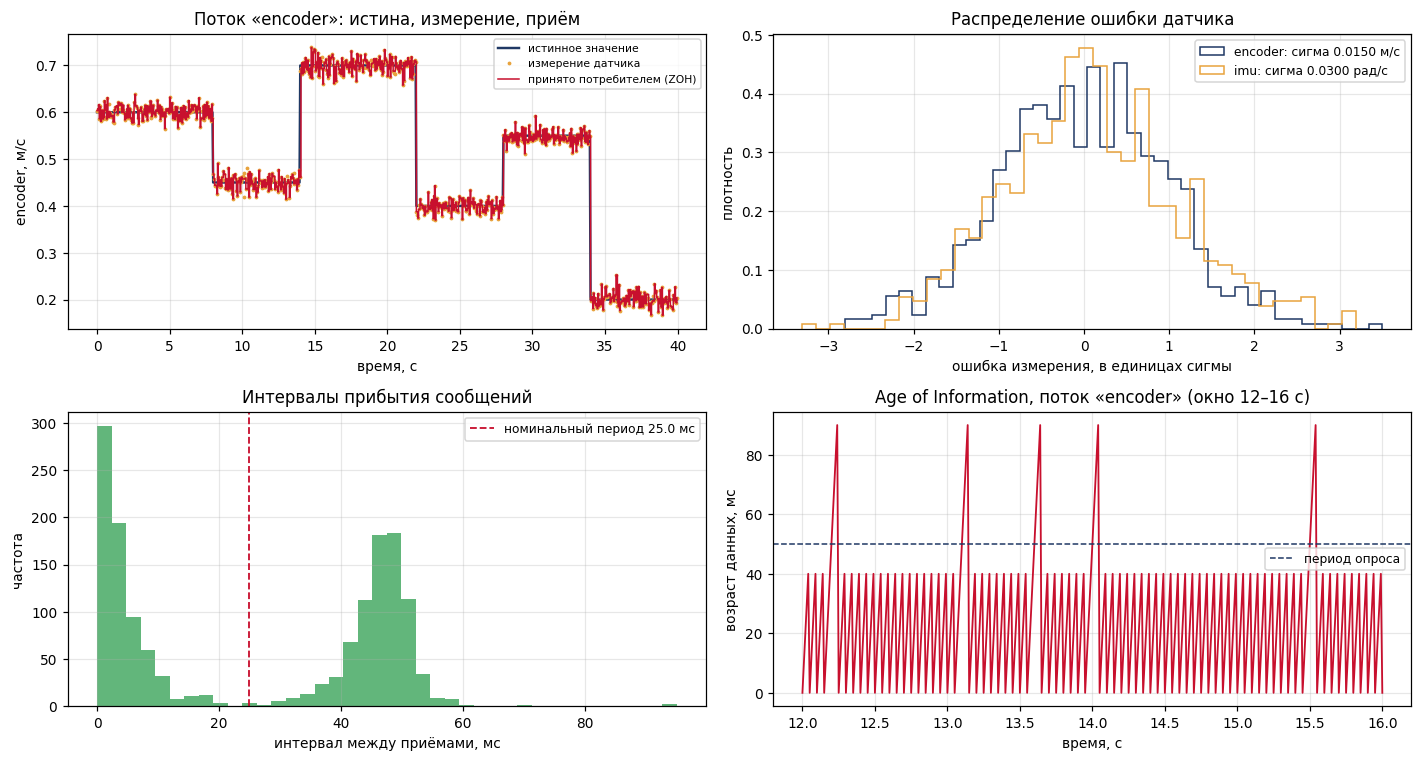

In [53]:
grid = np.arange(0.0, SIM_TIME, 0.01)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

# --- 1. исходный, измеренный и принятый ряды по первому потоку
stream = STREAMS[0]
src = meas[meas["sensor"] == stream]
rx_s = rx[rx["sensor"] == stream].sort_values("timestamp")
ax = axes[0, 0]
ax.plot(src["t"], src["truth"], lw=1.6, color="#1F3864", label="истинное значение", zorder=2)
ax.plot(src["t"], src["measured"], ".", ms=3, color="#E8A33D",
        label="измерение датчика", zorder=3)
ax.step(rx_s["timestamp"], rx_s["value"], where="post", lw=1.0, color="#C8102E",
        label="принято потребителем (ZOH)", zorder=4)
ax.set_xlabel("время, с"); ax.set_ylabel(f"{stream}, {UNITS[stream]}")
ax.set_title(f"Поток «{stream}»: истина, измерение, приём")
ax.grid(alpha=.3); ax.legend(fontsize=7)

# --- 2. ошибка измерения
ax = axes[0, 1]
for s, color in zip(STREAMS, ["#1F3864", "#E8A33D", "#2E9E4F"]):
    d = meas[meas["sensor"] == s].dropna(subset=["measured"])
    err = (d["measured"] - d["truth"]) / SIGMA[s]
    ax.hist(err, bins=40, histtype="step", lw=1.6, density=True, color=color,
            label=f"{s}: сигма {SIGMA[s]:.4f} {UNITS[s]}")
ax.set_xlabel("ошибка измерения, в единицах сигмы"); ax.set_ylabel("плотность")
ax.set_title("Распределение ошибки датчика")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 3. интервалы между принятыми сообщениями
ax = axes[1, 0]
inter = np.diff(rx["t_rx"].to_numpy()) * 1000
ax.hist(inter, bins=40, color="#2E9E4F", alpha=.75)
nominal = 1000.0 / (cfg["freq_hz"] * len(STREAMS))
ax.axvline(nominal, color="#C8102E", ls="--", lw=1.2,
           label=f"номинальный период {nominal:.1f} мс")
ax.set_xlabel("интервал между приёмами, мс"); ax.set_ylabel("частота")
ax.set_title("Интервалы прибытия сообщений")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 4. возраст информации
ax = axes[1, 1]
window = (grid >= 12.0) & (grid <= 16.0)          # окно 4 с: иначе пила не читается
aoi = age_of_information(rx_s, grid)
ax.plot(grid[window], aoi[window] * 1000, lw=1.2, color="#C8102E")
ax.axhline(1000.0 / cfg["freq_hz"], color="#1F3864", ls="--", lw=1.0,
           label="период опроса")
ax.set_xlabel("время, с"); ax.set_ylabel("возраст данных, мс")
ax.set_title(f"Age of Information, поток «{stream}» (окно 12–16 с)")
ax.grid(alpha=.3); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

## Часть 5. Исследование (3 балла)

Измените по одному параметру (доля потерь, частота публикации), остальные оставьте как в варианте. Постройте таблицу и график зависимости метрик от параметра.

In [54]:
def run_pipeline(variant_cfg: dict, loss_pct: float = None,
                 freq_hz: float = None) -> dict:
    """Полный прогон конвейера «датчик -> сообщения -> канал -> метрики».

    Меняется ровно один параметр, остальные берутся из конфигурации варианта:
    это однофакторный эксперимент.
    """
    local = dict(variant_cfg)
    if loss_pct is not None:
        local["loss_pct"] = loss_pct
    if freq_hz is not None:
        local["freq_hz"] = freq_hz

    generator = np.random.default_rng(local["seed"])
    local_meas = sample_measurements(truth, local, generator)
    local_messages = build_messages(local_meas)
    local_rx = transmit(local_messages, ChannelConfig(loss_pct=local["loss_pct"]), generator)
    result = channel_metrics(local_messages, local_rx, local_meas, local)
    return {"freq_hz": local["freq_hz"], "loss_pct": local["loss_pct"], **result}


first = STREAMS[0]
loss_sweep = pd.DataFrame([run_pipeline(cfg, loss_pct=p)
                           for p in [0, 2, 5, 10, 20, 30, 50]])[
    ["loss_pct", "messages_received", "loss_pct_actual", "rate_actual_hz",
     "longest_loss_burst", f"{first}_recon_rmse", f"{first}_max_gap_s",
     f"{first}_aoi_mean_s", f"{first}_aoi_max_s"]]

print(f"Влияние потерь пакетов (частота {cfg['freq_hz']} Гц, поток «{first}»)\n")
print(loss_sweep.to_string(index=False))

Влияние потерь пакетов (частота 20 Гц, поток «encoder»)

 loss_pct  messages_received  loss_pct_actual  rate_actual_hz  longest_loss_burst  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_mean_s  encoder_aoi_max_s
        0               1600            0.000          40.000                   0             0.01757               0.05              0.0200               0.04
        2               1576            1.500          39.400                   1             0.01757               0.15              0.0211               0.14
        5               1527            4.562          38.175                   2             0.01766               0.15              0.0227               0.14
       10               1449            9.438          36.225                   2             0.01776               0.15              0.0253               0.14
       20               1280           20.000          32.000                   4             0.01765               0.25              0.0316   

## Вывод

Опишите влияние частоты, шума и потерь на качество телеметрии. Каждый пункт — со ссылкой на
**ваши** числа: заданная и фактическая доля потерь, ошибка датчика и ошибка у потребителя,
что изменилось при изменении частоты и потерь.

*(ваш вывод)* Работа наглядно показала, что качество телеметрии зависит не только от точности самого прибора, но и от надёжности канала связи. Для моего варианта (20 Гц, 5% потерь) система работает стабильно, но задержка до 54 мс и устаревание данных до 0,19 с требуют обязательного учёта при настройке контуров управления роботом. Увеличение частоты опроса имеет смысл только при гарантированно низком проценте потерь в канале.


## Часть 6. Методическое задание (2 балла)

Разработайте **фрагмент урока (10–15 минут) или игру** для школьников по **одному** из трёх
выводов работы (см. «Смысл работы для будущего учителя»). Обязательно используйте **числа
своего варианта**.

| Пункт | Ваш ответ |
|---|---|
| Вывод работы (номер и формулировка) |потери в канале связи бьют по «свежести» данных: пока новое сообщение летит по радиоканалу или теряется, оператор вынужден удерживать на экране старое значение, и ошибка восстановленного сигнала растёт. |
| Класс и формат (урок, игра, кружок) |8–9 класс, кружок |
| Время |45 мин |
| Цель для учеников |понять, почему даже точный датчик может давать плохую картинку на экране оператора, и как потери в канале превращаются в «устаревание» информации |
| Материалы |Колаб, презентация |
| Числа вашего варианта (не менее двух) и как они используются |Частота 20 Гц — «робот» отправляет по 20 пакетов в секунду (по одному каждые 0,05 с). Ученики считают, сколько пакетов должно долететь за 5 секунд (100 штук).Потери 5 % (73 из 1600 пакетов) — из каждых 20 пакетов «робот» нарочно не отдаёт 1 (учитель заранее помечает их крестиком). Ученики видят, что до оператора дошло не 100, а ~95 пакетов.Recon RMSE для энкодера: 0,0147 → 0,0196 м/с — показываем на доске: ошибка самого датчика была 0,015, а у оператора стала 0,020. Разница — именно из-за пропущенных пакетов.AoI max = 0,19 с — в худший момент оператор видел данные, которым уже почти 0,2 секунды. Для робота, едущего 0,7 м/с, это 14 см «вслепую». |

**Ход фрагмента (3–5 шагов: что делает учитель, что делают ученики):**

1. Разминка (2 мин). Учитель делит класс на пары: один «робот (сидит у доски с листочками-пакетами, на каждом написано число  скорость колеса»), второй — оператор (сидит в 3 метрах, держит таблицу). Задача робота — передавать оператору по одному листочку каждые 0,05 с (учитель хлопает в ладоши как метроном). Оператор записывает последнее полученное число.
2. Идеальный канал (3 мин). Робот отдаёт все 20 пакетов подряд. Оператор записывает все 20 чисел. Учитель спрашивает: Насколько картина оператора совпадает с тем, что реально делал робот? ответ: полностью, ошибка только в шуме датчика.
3. Реальный канал с потерями 5 % (4 мин). Учитель забирает у робота каждый 20-й пакет это модель 5 % потерь. Оператор теперь иногда не получает новое число и продолжает держать в таблице предыдущее. Учитель останавливает игру и спрашивает оператора: Какое число у тебя сейчас записано? А какое на самом деле у робота? — числа расходятся.
4. Подсчёт и вывод (3 мин). Учитель показывает на доске числа из лабораторной: при 5 % потерь ошибка оператора выросла с 0,015 до 0,020 м/с, а в худший момент оператор смотрел на данные 190-миллисекундной давности. Для робота со скоростью 0,7 м/с это значит, что он проехал 13 см вслепую.

**Ключевой вопрос для учеников:** Если датчик сам по себе точный (ошибка всего 0,015), почему оператор на экране видит картинку с ошибкой 0,020? Куда делась точность?

**Проверка понимания (как узнать, что вывод усвоен, и какое заблуждение ловится):** Задать контрольный вопрос: «Представьте, что мы увеличили частоту опроса с 20 до 40 Гц, но потери остались 5 %. Станет ли картинка у оператора точнее?

---

**Критерии:** 1 балл — вывод передан без искажения и опирается на числа вашего варианта;
1 балл — фрагмент реализуем: возраст, время и материалы согласованы, есть ключевой вопрос и
проверка понимания.

**Идея для старта:** игра «Телеметрия с кубиком» — «датчик» называет числа, «канал» бросает
кубик (единица — сообщение потеряно), «экран» записывает только услышанное; электронная
таблица с `СЛЧИС()`; датчики смартфона или micro:bit. Не засчитывается общий текст без
действий учеников и фрагмент без чисел вашего варианта.

## Перед сдачей

- [ ] указаны ФИО, группа и вариант; параметры варианта не изменены вручную;
- [ ] не менее 30 с измерений, сообщения в формате `device_id / seq / timestamp / sensor / value`;
- [ ] посчитаны четыре обязательные метрики;
- [ ] графики подписаны;
- [ ] исследование потерь и частоты выполнено;
- [ ] вывод опирается на ваши числа;
- [ ] заполнен шаблон части 6.